# Australia right now: fire hotspots, incidents and who lives near them, at one moment

This notebook rebuilds the numbers of the *Australia right now* showcase from the public feeds as they were read at one
moment on a weekday morning (the time is in `../data/numbers.json`).

**Read this first**

- **Public data at a point in time, not an official warning service.** The feeds change every few minutes; this is one
  reading of them, kept. **For official warnings, check your state emergency service.**
- **A hotspot is a hot pixel seen from space, not a confirmed fire.** Geoscience Australia's DEA Hotspots lists what the
  polar-orbiting satellites (VIIRS, MODIS, AVHRR) saw in the 24 hours; the geostationary Himawari detections are left out.
  Steelworks, refineries, smelters, power stations and gas flares show up too; those within 400 m of such a site in
  OpenStreetMap are flagged and left out of the counts.
- **Residents are the 2021 Census usual residents** of each mesh block, spread evenly through it, so a block partly
  inside a 5 km zone counts in proportion. They are where people lived in 2021, not where they are now.
- **Warning areas** are the outlines the NSW Rural Fire Service and the Queensland Fire Department published with their
  incidents at Advice level or higher at that moment.

The notebook reads only `../data`, plus the ABS mesh block files it downloads.

In [1]:
import json, os, zipfile, urllib.request
import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt, shapely
DATA = '../data'
ALB = 'EPSG:9473'   # GDA2020 Australian Albers, metres
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
N = json.load(open(f'{DATA}/numbers.json'))
print('Snapshot:', N['snapshot']['local'], '(UTC', N['snapshot']['utc'] + ')')

Snapshot: Tuesday 24 November 2026 at 8:50 am AEDT (UTC 2026-11-23T21:50:19.000Z)


## The hotspots

DEA Hotspots for the 24 hours before the snapshot, on land in an Australian state or territory. `industrial` marks the
ones at an industrial site.

In [2]:
hot = gpd.read_file(f'{DATA}/geometry/hotspots.geojson')
print(len(hot), 'hotspots in the 24 hours;', int(hot.industrial.sum()), 'at industrial sites, left out')
fires = hot[~hot.industrial]
six = fires[fires.hours_since < 6]
print(len(fires), 'counted;', len(six), 'in the last 6 hours')
by = pd.DataFrame({'24 hours': fires.groupby('state').size(), 'last 6 hours': six.groupby('state').size()}).fillna(0).astype(int).sort_values('24 hours', ascending=False)
by

25724 hotspots in the 24 hours; 255 at industrial sites, left out
25469 counted; 3903 in the last 6 hours


,24 hours,last 6 hours
state,,
QLD,10608,607
WA,8342,2370
NT,3427,866
SA,2926,59
NSW,141,1
VIC,21,0
TAS,4,0


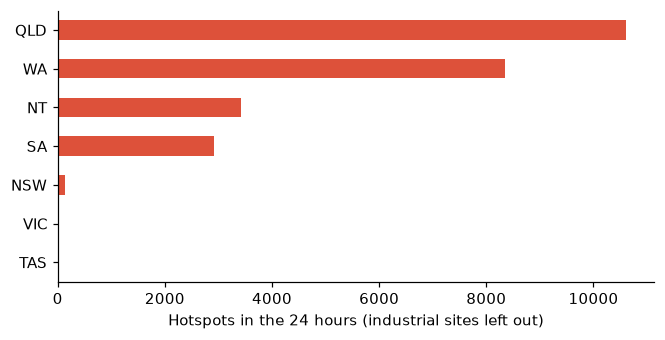

In [3]:
ax = by['24 hours'].plot.barh(color='#dd513a', figsize=(7, 3.2)); ax.invert_yaxis(); ax.set_xlabel('Hotspots in the 24 hours (industrial sites left out)'); ax.set_ylabel('')
plt.show()

In [4]:
ind = hot[hot.industrial].groupby('site').size().sort_values(ascending=False).head(12)
ind.rename('hotspots left out').to_frame()

,hotspots left out
site,
Sebastopol Solar Farm,39
Pluto LNG Park,32
Bomen Solar Farm,31
industrial land,24
Wyalong Solar Farm,22
Griffith Solar Farm,13
Junee Solar Farm,13
Chevron Wheatstone Project,8
Walla Walla Solar Farm,8


## Incidents and warning areas

The NSW RFS major incidents and the Queensland Fire Department's current bushfires at the snapshot, with the level each
agency gave. Only incidents at Advice level or higher with an outline are warning areas here.

In [5]:
inc = gpd.read_file(f'{DATA}/geometry/incidents.geojson')
warn = gpd.read_file(f'{DATA}/geometry/warnings.geojson')
display(inc.groupby(['state', 'level']).size().rename('incidents').to_frame())
warn[['state', 'name', 'level', 'size_ha']]

incidents
state level                    
NSW   Advice                  8
      Not Applicable         11
QLD   Advice                  1
      Information            18

,state,name,level,size_ha
0,NSW,BEECROFT WEAPONS RANGE BEECROFT PENINSULA,Advice,410.0
1,NSW,"COLLINS CREEK RD, COLLINS CREEK",Advice,1.0
2,NSW,"COONABARABRAN RD, ULAMAMBRI",Advice,28.0
3,NSW,"H POTS FIRE, CESSNOCK",Advice,101.0
4,NSW,"RED POINT RD, WOLLUMBOOLA",Advice,0.0
5,NSW,"ULAN RD, TURILL",Advice,1.0
6,QLD,AVOID SMOKE - Mapoon - fire as at 1:38pm Monda...,Advice,NaN


## Residents within 5 km

The 2021 Census mesh block counts and the mesh block boundaries (ABS, CC BY 4.0) are downloaded here: about 230 MB and
15 MB. A mesh block partly inside a zone counts in proportion to its area inside.

In [6]:
os.makedirs('abs', exist_ok=True)
MB_ZIP = 'abs/MB_2021_AUST_SHP_GDA2020.zip'
if not os.path.exists(MB_ZIP):
    urllib.request.urlretrieve('https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/edition-3-july-2021-june-2026/access-and-downloads/digital-boundary-files/MB_2021_AUST_SHP_GDA2020.zip', MB_ZIP)
COUNTS = 'abs/mb_counts_2021.xlsx'
if not os.path.exists(COUNTS):
    urllib.request.urlretrieve('https://www.abs.gov.au/census/guide-census-data/mesh-block-counts/2021/Mesh%20Block%20Counts%2C%202021.xlsx', COUNTS)
sheets = [s for s in pd.ExcelFile(COUNTS).sheet_names if s.startswith('Table')]
cnt = pd.concat([pd.read_excel(COUNTS, s, skiprows=6) for s in sheets])
cnt = cnt[pd.to_numeric(cnt['MB_CODE_2021'], errors='coerce').notna()]
cnt['MB_CODE21'] = cnt['MB_CODE_2021'].astype('int64').astype(str)
cnt['Person'] = pd.to_numeric(cnt['Person'], errors='coerce').fillna(0)
mb = gpd.read_file('zip://' + MB_ZIP, columns=['MB_CODE21', 'STE_NAME21'])
mb = mb[mb.geometry.notna()].merge(cnt[['MB_CODE21', 'Person']], on='MB_CODE21')
mb = mb[mb.Person > 0].to_crs(ALB); mb['area'] = mb.area
print(f'{len(mb):,} populated mesh blocks, {int(mb.Person.sum()):,} residents')

279,803 populated mesh blocks, 25,365,959 residents


In [7]:
def residents(zone):
    sub = mb.iloc[mb.sindex.query(zone, predicate='intersects')].copy()
    sub['people'] = sub.Person * (sub.geometry.intersection(zone).area / sub.area).clip(0, 1)
    return sub
out = {}
for name, pts in [('a hotspot in the 24 hours', fires), ('a hotspot in the last 6 hours', six)]:
    z = shapely.union_all(pts.to_crs(ALB).geometry.buffer(5000, 16).values)
    s = residents(z); out[name] = s.groupby('STE_NAME21').people.sum()
    print(f'Within 5 km of {name}: {s.people.sum():,.0f} residents')
zw = shapely.union_all(warn.to_crs(ALB).geometry.buffer(5000, 16).values)
print(f"Within 5 km of a warning area: {residents(zw).people.sum():,.0f} residents")
pd.DataFrame(out).fillna(0).round().astype(int)

Within 5 km of a hotspot in the 24 hours: 180,381 residents


Within 5 km of a hotspot in the last 6 hours: 5,409 residents


Within 5 km of a warning area: 26,323 residents


,a hotspot in the 24 hours,a hotspot in the last 6 hours
STE_NAME21,,
New South Wales,4326,42
Northern Territory,4263,22
Queensland,33118,3730
South Australia,2,0
Tasmania,217,0
Victoria,5900,0
Western Australia,132555,1614


The page's figures (`numbers.json`) for comparison:

In [8]:
print('24 hours:', N['people']['hotspots_24h']['people'], ' 6 hours:', N['people']['hotspots_6h']['people'], ' warning areas:', N['warnings']['people_5km'])

24 hours: 180381  6 hours: 5409  warning areas: 26323


## NSW fire danger ratings

The RFS feed gives each fire weather district's rating with the councils in it, but no outlines; the districts here are
those councils' 2021 Local Government Areas joined together.

,"residents, 2021"
today,
High,335317
Moderate,7415149
No rating,311295


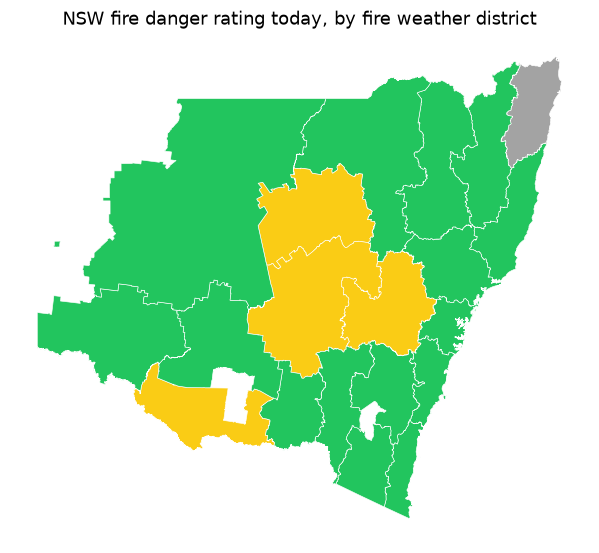

In [9]:
fdr = gpd.read_file(f'{DATA}/geometry/fdr_nsw.geojson')
fdr['today'] = fdr.today.fillna('None').replace({'None': 'No rating'})
display(fdr.groupby('today').people.sum().rename('residents, 2021').to_frame())
COL = {'High': '#facc15', 'Moderate': '#22c55e', 'No rating': '#a3a3a3'}
ax = fdr.plot(color=fdr.today.map(COL), edgecolor='white', linewidth=0.4, figsize=(7, 6)); ax.set_axis_off(); ax.set_title('NSW fire danger rating today, by fire weather district')
plt.show()

## Sources and licences

DEA Hotspots, © Commonwealth of Australia (Geoscience Australia), CC BY 4.0. NASA FIRMS active fire data (VIIRS, MODIS),
NASA open data. NSW RFS major incidents and fire danger ratings, © State of New South Wales (NSW Rural Fire Service),
CC BY 4.0. Queensland current bushfires, © State of Queensland (Queensland Fire Department), CC BY 4.0. ABS Census 2021
Mesh Block Counts and ASGS Edition 3 boundaries, CC BY 4.0. Roads, hospitals and industrial sites © OpenStreetMap
contributors, ODbL 1.0. Made with [Plotlay](https://www.getplotlay.com). For official warnings, check your state
emergency service.